# Qwen3.5 weight editing: saved-output replay or fresh GPU experiment

Default `RUN_GPU=False`: replay96 real saved generations on CPU, re-grade and plot; no model download, GPU allocation or HF credential. First use downloads the small pinned dataset and saved results when not present locally.

Set `RUN_GPU=True` only with a separately authorized existing L4, HF_TOKEN supplied in kernel memory, and host-enforced WSP_DEADLINE_EPOCH. It requests96 fresh formal outputs; no runtime is allocated or automatically stopped by this Notebook.

The published evidence is80 outputs from an interrupted full run plus16 from a completion run. Frozen authored/executed source and lifecycle receipts are under evidence/. This is not a single-session96-output Run all or a replay of Astra discovery.


In [1]:
from pathlib import Path
import os, sys, json, time, hashlib, random, gc, importlib.metadata, subprocess, venv, zipfile
RUN_GPU = False  # default: CPU re-score of saved real outputs; True requires new GPU authorization
ENV_READY = DATA_READY = CKPT_READY = GENERATION_READY = False
OUTPUT_DIR = Path('/content/weight-space-programming-output')
ROOT = OUTPUT_DIR
ARMS = ('base', 'author_p50c', 'random_control')
BUDGETS = (8192, 32768)
MODEL_REV = '2fc06364715b967f1860aea9cf38778875588b17'
UPSTREAM_REV = '4d09ba6d6a7e891dd8063974dfe81b3d78e3494f'
DATA_REV = '6e4ed1a2a79af7d8630a6b768ec859cb5af4d3be'
STACK = {'vllm':'0.25.0', 'transformers':'5.17.0', 'math-verify':'0.9.0', 'huggingface-hub':'1.14.0', 'safetensors':'0.8.0'}
EXPECTED_SOURCE_SHA256 = '35dc41080a3680858b27fa7e0533d2d547825316fc5dafe5d316f4ccc5a06132'
EXPECTED_IDS = ['test/number_theory/459.json', 'test/counting_and_probability/116.json', 'test/precalculus/819.json', 'test/intermediate_algebra/662.json', 'test/algebra/2102.json', 'test/algebra/114.json', 'test/prealgebra/378.json', 'test/counting_and_probability/159.json', 'test/number_theory/46.json', 'test/algebra/694.json', 'test/algebra/841.json', 'test/number_theory/234.json', 'test/intermediate_algebra/101.json', 'test/prealgebra/2086.json', 'test/number_theory/1055.json', 'test/number_theory/978.json']
os.environ['VLLM_WORKER_MULTIPROC_METHOD'] = 'spawn'
os.environ['USE_TF'] = '0'
os.environ['USE_FLAX'] = '0'
# Proposed stack: parent/runner must review compatibility before paid execution.
STACK_REVIEWED = True
CONFIG = dict(arms=ARMS, budgets=BUDGETS, n_questions=16, selection_seed=20261104,
              control_seed=20261104, thinking=True, temperature=0.6, top_p=0.95,
              top_k=20, presence_penalty=1.5, n=1, max_model_len=34816,
              gpu_memory_utilization=0.8, max_num_seqs=16, enforce_eager=True,
              model_revision=MODEL_REV, upstream_revision=UPSTREAM_REV, dataset_revision=DATA_REV)
def deadline():
    if RUN_GPU:
        end = float(os.environ['WSP_DEADLINE_EPOCH'])
        if not (0 < end - time.time()):
            raise TimeoutError('Host working deadline reached; preserve partial artifacts and stop runtime externally')
def write_json(path, value):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    temp = path.with_suffix(path.suffix + '.tmp')
    temp.write_text(json.dumps(value, indent=2, ensure_ascii=False), encoding='utf-8')
    temp.replace(path)

In [2]:
import hashlib, json, random, re
from collections import defaultdict
import numpy as np

def sha_bytes(value):
    return hashlib.sha256(value).hexdigest()

def bf16_to_f32(bits):
    return (np.asarray(bits, dtype=np.uint32) << 16).view(np.float32)

def bf16_bits(values):
    values = np.ascontiguousarray(values, dtype=np.float32)
    if not np.isfinite(values).all():
        raise ValueError('Only finite weight values are supported')
    u = values.view(np.uint32).astype(np.uint64)
    return ((u + 0x7fff + ((u >> 16) & 1)) >> 16).astype(np.uint16)

def sparse_rebuild(base, indices, values):
    base = np.asarray(base)
    indices, values = np.asarray(indices), np.asarray(values)
    if base.dtype != np.uint16 or indices.dtype.kind not in 'iu' or values.dtype != np.uint16:
        raise ValueError('Expected raw uint16 BF16 and integer indices')
    if indices.ndim != 1 or values.shape != indices.shape or len(np.unique(indices)) != len(indices):
        raise ValueError('Sparse index/value shape or duplicate index')
    if len(indices) and (indices.min() < 0 or indices.max() >= base.size):
        raise ValueError('Index outside tensor')
    result = base.copy().reshape(-1)
    result[indices] = values
    return result.reshape(base.shape)

def random_control(base, edited, rng):
    b, e = bf16_to_f32(base), bf16_to_f32(edited)
    delta = e - b
    columns = np.flatnonzero(np.any(base != edited, axis=0))
    shuffled = np.zeros_like(delta)
    for col in columns:
        shuffled[:, col] = delta[rng.permutation(delta.shape[0]), col]
    control = bf16_bits(b + shuffled)
    actual = bf16_to_f32(control) - b
    stats = dict(columns=columns.tolist(), requested_norm=float(np.linalg.norm(shuffled.astype(np.float64))),
                 author_norm=float(np.linalg.norm(delta.astype(np.float64))),
                 rounded_norm=float(np.linalg.norm(actual.astype(np.float64))),
                 rounding_error=float(np.linalg.norm((actual-shuffled).astype(np.float64))),
                 changed_entries=int(np.count_nonzero(control != base)),
                 changed_columns=int(np.count_nonzero(np.any(control != base, axis=0))))
    if not np.isclose(stats['requested_norm'], stats['author_norm'], rtol=1e-12, atol=1e-12):
        raise ValueError('Control delta norm changed before rounding')
    return control, stats

def select_questions(rows, count=16, seed=20261104):
    ordered = list(rows)
    random.Random(seed).shuffle(ordered)
    result = ordered[:count]
    if len(result) != count or len({r['unique_id'] for r in result}) != count:
        raise ValueError('Insufficient or duplicate question IDs')
    return result

def question_seed(problem_id):
    return int.from_bytes(hashlib.sha256(('20261104:'+str(problem_id)).encode()).digest()[:4], 'little') % (2**31)

def build_prompt(problem):
    return problem + chr(10) + 'Please reason step by step, and put your final answer within \\boxed{}.'

def last_boxed(text):
    found = []
    for match in re.finditer(r'\\boxed\s*\{', text):
        start, depth = match.end(), 1
        for i in range(start, len(text)):
            if text[i] == '{' and (i == 0 or text[i-1] != chr(92)):
                depth += 1
            elif text[i] == '}' and (i == 0 or text[i-1] != chr(92)):
                depth -= 1
                if depth == 0:
                    found.append(text[start:i])
                    break
    return found[-1] if found else None

def repetition(tokens, n=4):
    grams = [tuple(tokens[i:i+n]) for i in range(max(0, len(tokens)-n+1))]
    return 0.0 if not grams else 1.0 - len(set(grams))/len(grams)

def aggregate(raw):
    groups = defaultdict(list)
    seen = set()
    for r in raw:
        key = (r['arm'], r['budget'], r['problem_id'])
        if key in seen:
            raise ValueError('Duplicate generation key')
        seen.add(key)
        groups[(r['arm'], r['budget'])].append(r)
    result = []
    for (arm, budget), rows in sorted(groups.items()):
        result.append(dict(arm=arm, budget=budget, n=len(rows), correct=sum(bool(r['correct']) for r in rows),
            finish_length=sum(r['finish_reason']=='length' for r in rows),
            eos_stop=sum(bool(r['eos_stop']) for r in rows),
            thinking_closed=sum(bool(r['thinking_closed']) for r in rows),
            has_boxed=sum(r['boxed'] is not None for r in rows),
            mean_tokens=sum(len(r['token_ids']) for r in rows)/len(rows),
            mean_repetition=sum(r['repetition_4gram'] for r in rows)/len(rows)))
    pairs=[]
    index={(r['arm'],r['budget'],r['problem_id']):r for r in raw}
    for r in raw:
        if r['arm']=='base':
            for arm in ('author_p50c','random_control'):
                other=index.get((arm,r['budget'],r['problem_id']))
                if other:
                    pairs.append(dict(arm=arm,budget=r['budget'],problem_id=r['problem_id'],
                         rescue=not r['correct'] and bool(other['correct']),
                         regression=bool(r['correct']) and not other['correct'],
                         base_thinking_closed=r['thinking_closed'], edited_thinking_closed=other['thinking_closed']))
    return dict(groups=result, pairs=pairs, total=len(raw))

def validate_complete(raw, ids, arms=('base','author_p50c','random_control'), budgets=(8192,32768)):
    actual={(r['arm'],r['budget'],r['problem_id']) for r in raw}
    expected={(a,b,i) for a in arms for b in budgets for i in ids}
    if actual != expected or len(raw) != len(expected):
        raise ValueError('Missing, extra or duplicate outputs: completion forbidden')
    return True

## Isolated installation (opt-in only)
The base interpreter and preloaded package versions are captured before installation. The installer is the only subprocess: experiment code, downloads, editing, generation, grading and charting stay in native cells. Stack pins require review; GPU execution is intentionally gated until reviewed. No `trust_remote_code` or upstream Python execution.

In [3]:
if RUN_GPU:
    deadline()
    if not STACK_REVIEWED:
        raise RuntimeError('Review and freeze STACK before paid GPU work')
    ROOT.mkdir(parents=True, exist_ok=True)
    base_versions = {p: importlib.metadata.version(p) for p in ('torch','numpy','matplotlib')}
    loaded_versions = {p: getattr(sys.modules[p], '__version__', None) for p in base_versions if p in sys.modules}
    write_json(ROOT/'environment/base.json', dict(distributions=base_versions, loaded=loaded_versions, python=sys.version))
    write_json(ROOT/'environment.json', dict(base_distributions=base_versions, preloaded=loaded_versions, python=sys.version, stack_proposal=STACK))
    write_json(ROOT/'audit.json', dict(config=CONFIG, status='setup', single_decode_seed_per_problem=True))
    write_json(ROOT/'progress.json', dict(status='setup', completed=0, expected=96))
    write_json(ROOT/'summary.json', dict(groups=[],pairs=[],total=0))
    isolated = ROOT/'venv'
    venv.EnvBuilder(with_pip=False, system_site_packages=True).create(isolated)
    constraints = ROOT/'environment/base-constraints.txt'
    constraints.write_text(''.join(f'{k}=={v}\n' for k,v in base_versions.items() if k != 'torch'))
    env = {k:v for k,v in os.environ.items() if k not in ('HF_TOKEN','HUGGING_FACE_HUB_TOKEN','UV_SYSTEM_PYTHON')}
    wheel_specs = ['torch @ https://download-r2.pytorch.org/whl/cu129/torch-2.11.0%2Bcu129-cp313-cp313-manylinux_2_28_x86_64.whl#sha256=fde1830d7f79641680865759dc57780e94a9de7e68a82ed61973e9bc7af29423', 'torchvision @ https://download-r2.pytorch.org/whl/cu129/torchvision-0.26.0%2Bcu129-cp313-cp313-manylinux_2_28_x86_64.whl#sha256=4a4d4ead35f916ea4e64d8cc7b8177e4780365da7acd0197cddff922a0056c8a', 'torchaudio @ https://download-r2.pytorch.org/whl/cu129/torchaudio-2.11.0%2Bcu129-cp313-cp313-manylinux_2_28_x86_64.whl#sha256=45103fac849ffee337976ff19eac81725b3396e2c18e3f48ed92ba7669cb32d7']
    if sys.version_info[:2] != (3, 13):
        raise RuntimeError('Pinned cu129 wheels require Python 3.13')
    smi=subprocess.run(['nvidia-smi','--query-gpu=name,driver_version','--format=csv,noheader'],capture_output=True,text=True,check=True,timeout=15).stdout.strip()
    gpu_name,driver=smi.split(',')
    if 'L4' not in gpu_name or tuple(map(int,driver.strip().split('.'))) < (575,51,3):
        raise RuntimeError('Requires authorized L4 and cu129-capable driver')
    install = subprocess.run([sys.executable,'-m','pip','--python',str(isolated/'bin/python'),
        'install','-c',str(constraints),'--only-binary=torch,torchvision,torchaudio,vllm',*[f'{k}=={v}' for k,v in STACK.items()],*wheel_specs],
        capture_output=True, text=True, env=env, timeout=min(600,max(1,int(float(os.environ['WSP_DEADLINE_EPOCH'])-time.time()))))
    (ROOT/'environment/install.stdout').write_text(install.stdout)
    (ROOT/'environment/install.stderr').write_text(install.stderr)
    install.check_returncode()
    import sysconfig
    site = isolated/'lib'/f'python{sys.version_info.major}.{sys.version_info.minor}'/'site-packages'
    sys.path.insert(0,str(site))
    importlib.invalidate_caches()
    for name in list(sys.modules):
        if name=='huggingface_hub' or name.startswith('huggingface_hub.'):
            del sys.modules[name]
    os.environ['VIRTUAL_ENV']=str(isolated)
    os.environ['PATH']=str(isolated/'bin')+os.pathsep+os.environ['PATH']
    sys.executable=str(isolated/'bin/python')
    for p, version in base_versions.items():
        if p!='torch' and importlib.metadata.version(p) != version:
            raise RuntimeError(f'Base version changed: {p}')
    for p, version in STACK.items():
        if importlib.metadata.version(p) != version:
            raise RuntimeError(f'Stack version mismatch: {p}')
    write_json(ROOT/'environment/installed.json', {p:importlib.metadata.version(p) for p in (*STACK,*base_versions)})
    write_json(ROOT/'provenance/config.json', CONFIG)
    write_json(ROOT/'environment.json',dict(base_distributions=base_versions,preloaded=loaded_versions,installed={p:importlib.metadata.version(p) for p in (*STACK,*base_versions)},python=sys.version))
    ENV_READY = True


## Pinned bytes → predeclared selection → verified checkpoints
The public multimodal config is retained with native language_model_only=True; only model.language_model.* tensors are saved, without renaming. vLLM 0.25 registers the conditional-generation architecture, not the text-only class used by newer releases. Exact BF16 hash gates precede inference.


In [4]:
if RUN_GPU and ENV_READY:
    deadline()
    from urllib.request import urlopen
    from huggingface_hub import hf_hub_download
    token = os.environ.get('HF_TOKEN')  # optional for public artifacts; never print/persist
    raw_url = f'https://raw.githubusercontent.com/RikiyaT/lm_understand-logs/{UPSTREAM_REV}/exp8_math/'
    source_dir = ROOT/'sources'
    source_dir.mkdir(exist_ok=True)
    def fetch_relative(relative):
        deadline()
        data = urlopen(raw_url+relative, timeout=60).read()
        path = source_dir/relative
        path.parent.mkdir(parents=True,exist_ok=True)
        path.write_bytes(data)
        return path
    manifest_path = fetch_relative('runs/p50c/edit/manifest.json')
    edit_path = fetch_relative('runs/p50c/edit/edit.npz')
    text_config = fetch_relative('base_model/Qwen3.5-0.8B-text/config.json')
    generation_config = fetch_relative('base_model/Qwen3.5-0.8B-text/generation_config.json')
    full_model_config = Path(hf_hub_download('Qwen/Qwen3.5-0.8B','config.json',revision=MODEL_REV,token=token))
    data_path = Path(hf_hub_download('HuggingFaceH4/MATH-500','test.jsonl',repo_type='dataset',revision=DATA_REV,token=token))
    data_bytes = data_path.read_bytes()
    if sha_bytes(data_bytes) != EXPECTED_SOURCE_SHA256:
        raise ValueError('Pinned dataset byte hash mismatch')
    (source_dir/'test.jsonl').write_bytes(data_bytes)
    all_rows = [json.loads(line) for line in data_bytes.splitlines() if line.strip()]
    if len(all_rows) != 500:
        raise ValueError('Pinned MATH-500 size mismatch')
    selected = select_questions(all_rows)
    if [r['unique_id'] for r in selected] != EXPECTED_IDS:
        raise ValueError('Frozen predeclared selection mismatch')
    selection = dict(dataset_sha256=sha_bytes(data_bytes), seed=20261104,
                     ordered_ids=[r['unique_id'] for r in selected])
    selection['selection_sha256'] = sha_bytes(json.dumps(selection,sort_keys=True).encode())
    write_json(ROOT/'provenance/selection.json',selection)
    # Selection is frozen above, before any generation or grading.
    index_path=Path(hf_hub_download('Qwen/Qwen3.5-0.8B','model.safetensors.index.json',revision=MODEL_REV,token=token))
    index=json.loads(index_path.read_text())
    shards=sorted(set(index['weight_map'].values()))
    if shards != ['model.safetensors-00001-of-00001.safetensors']:
        raise ValueError('Unexpected pinned shard layout')
    shard_path=Path(hf_hub_download('Qwen/Qwen3.5-0.8B',shards[0],revision=MODEL_REV,token=token))
    tokenizer_files={}
    for filename in ('tokenizer.json','tokenizer_config.json','chat_template.jinja','preprocessor_config.json'):
        tokenizer_files[filename]=Path(hf_hub_download('Qwen/Qwen3.5-0.8B',filename,revision=MODEL_REV,token=token))
    input_hashes={str(p.relative_to(source_dir)):sha_bytes(p.read_bytes()) for p in source_dir.rglob('*') if p.is_file()}
    input_hashes.update(model_shard=sha_bytes(shard_path.read_bytes()),model_index=sha_bytes(index_path.read_bytes()))
    write_json(ROOT/'provenance/input-hashes.json',input_hashes)
    DATA_READY = True


In [5]:
if RUN_GPU and DATA_READY:
    deadline()
    import torch
    from safetensors.torch import load_file, save_file
    if not torch.cuda.is_available():
        raise RuntimeError('CUDA unavailable; do not silently change device/precision')
    write_json(ROOT/'environment/gpu.json',dict(torch=torch.__version__, cuda=torch.version.cuda,
        name=torch.cuda.get_device_name(0), total_memory=torch.cuda.get_device_properties(0).total_memory))
    tensors=load_file(str(shard_path),device='cpu')
    tensors={k:v for k,v in tensors.items() if k.startswith('model.language_model.') or k=='lm_head.weight'}
    manifest=json.loads(manifest_path.read_text())
    if manifest['changed_tensors'] != 2 or len(manifest['tensors']) != 2:
        raise ValueError('Unexpected edit tensor count')
    replacements={'author_p50c':{}, 'random_control':{}}
    records=[]
    rng=np.random.default_rng(20261104)
    with np.load(edit_path,allow_pickle=False) as z:
        for i,t in enumerate(manifest['tensors']):
            deadline()
            name=t['name']
            base=tensors[name]
            if base.dtype != torch.bfloat16 or list(base.shape)!=t['shape'] or t['form']!='sparse':
                raise ValueError('Unexpected dtype/shape/edit form')
            bits=base.contiguous().view(torch.uint16).numpy().copy()
            if sha_bytes(bits.tobytes()) != t['base_sha256']:
                raise ValueError('Base tensor hash mismatch')
            edited=sparse_rebuild(bits,z[f't{i}_idx'],z[f't{i}_val'])
            if sha_bytes(edited.tobytes()) != t['edited_sha256']:
                raise ValueError('Author edited hash mismatch')
            if np.count_nonzero(edited!=bits)!=t['changed_entries']:
                raise ValueError('Changed-entry mismatch')
            control,stats=random_control(bits,edited,rng)
            if len(stats['columns'])!=64:
                raise ValueError('Expected 64 edited columns')
            replacements['author_p50c'][name]=torch.from_numpy(edited).view(torch.bfloat16)
            replacements['random_control'][name]=torch.from_numpy(control).view(torch.bfloat16)
            records.append(dict(name=name,base_sha256=t['base_sha256'],author_sha256=t['edited_sha256'],
                                control_sha256=sha_bytes(control.tobytes()),**stats))
    write_json(ROOT/'provenance/checkpoint-hashes-delta-norms.json',records)
    write_json(ROOT/'audit.json',dict(config=CONFIG,selection=selection,input_hashes=input_hashes,delta_norms=records,status='checkpoints_verified',single_decode_seed_per_problem=True))
    for arm in ARMS:
        deadline()
        dest=ROOT/'checkpoints'/arm
        dest.mkdir(parents=True,exist_ok=True)
        (dest/'config.json').write_bytes(full_model_config.read_bytes())
        (dest/'generation_config.json').write_bytes(generation_config.read_bytes())
        for filename,path in tokenizer_files.items():
            (dest/filename).write_bytes(path.read_bytes())
        weights=dict(tensors)
        weights.update(replacements.get(arm,{}))
        save_file(weights,str(dest/'model.safetensors'),metadata={'format':'pt'})
        write_json(ROOT/'provenance'/f'{arm}-checkpoint.json',dict(
            weight_sha256=sha_bytes((dest/'model.safetensors').read_bytes()), tensor_names=sorted(weights)))
    del tensors,weights,replacements,base
    gc.collect()
    CKPT_READY = True


## Strict scoring with bounded stages
Math parsing and symbolic verification each have a one-second timeout. Missing boxes are false; parsing failures retain explicit diagnostics. The real math-verify positive/negative/fraction fixtures are tested locally before allocation.


In [6]:
def grade_boxed(text, answer):
    from math_verify import parse, verify, LatexExtractionConfig
    boxed=last_boxed(text)
    if boxed is None:
        return dict(correct=False,boxed=None,grade_error=None)
    try:
        target=parse('$'+str(answer)+'$',extraction_config=[LatexExtractionConfig()],parsing_timeout=1,raise_on_error=True)
        prediction=parse('$'+chr(92)+'boxed{'+boxed+'}$',extraction_config=[LatexExtractionConfig()],parsing_timeout=1,raise_on_error=True)
        return dict(correct=bool(target and prediction and verify(target,prediction,timeout_seconds=1,raise_on_error=True)),boxed=boxed,grade_error=None)
    except Exception as exc:
        return dict(correct=False,boxed=boxed,grade_error=type(exc).__name__)


## Sequential engines; durable raw output before grading
One engine at a time. No external worker launch or model subprocess wrapper. A deadline check occurs between stages and questions; the host must enforce the hard deadline during a long generation call and stop the runtime. Engine cleanup is in `finally`; a failure aborts rather than silently running the next arm. The ZIP cell can be run separately after failure to package partial generations.jsonl; it will not write COMPLETE.

In [7]:
if RUN_GPU and CKPT_READY:
    deadline()
    from vllm import LLM, SamplingParams
    from transformers import AutoTokenizer
    from vllm.distributed.parallel_state import cleanup_dist_env_and_memory
    raw_path=ROOT/'generations.jsonl'
    if raw_path.exists() and raw_path.stat().st_size:
        raise RuntimeError('Refuse to append a new experiment to an existing raw run')
    def gpu_processes():
        probe=subprocess.run(['nvidia-smi','--query-compute-apps=pid','--format=csv,noheader,nounits'],capture_output=True,text=True,check=True,timeout=15)
        return sorted({int(line.strip()) for line in probe.stdout.splitlines() if line.strip().isdigit()})
    baseline_pids=set(gpu_processes())
    scored_so_far=[]
    for arm in ARMS:
        deadline()
        llm=None
        try:
            ckpt=str(ROOT/'checkpoints'/arm)
            tok=AutoTokenizer.from_pretrained(ckpt,trust_remote_code=False,local_files_only=True)
            llm=LLM(model=ckpt,tokenizer=ckpt,trust_remote_code=False,dtype='bfloat16',seed=0,
                enforce_eager=True,max_num_seqs=16,max_model_len=34816,gpu_memory_utilization=0.8,language_model_only=True)
            smoke=llm.generate(['Reply with the word ready.'],SamplingParams(max_tokens=8,temperature=0,seed=0),use_tqdm=False)
            write_json(ROOT/'provenance'/f'{arm}-smoke.json',dict(text=smoke[0].outputs[0].text,token_ids=list(smoke[0].outputs[0].token_ids),not_formal_sample=True))
            del smoke
            for budget in BUDGETS:
                deadline()
                prepared=[]
                for row in selected:
                    seed=question_seed(row['unique_id'])
                    user_prompt=build_prompt(row['problem'])
                    prompt=tok.apply_chat_template([{'role':'user','content':user_prompt}],tokenize=False,add_generation_prompt=True,enable_thinking=True)
                    encoded=tok.encode(prompt,add_special_tokens=False)
                    if len(encoded)+budget > CONFIG['max_model_len']:
                        raise ValueError('Prompt exceeds predeclared context reserve')
                    params=SamplingParams(n=1,temperature=0.6,top_p=0.95,top_k=20,presence_penalty=1.5,max_tokens=budget,seed=seed)
                    prepared.append((row,seed,user_prompt,prompt,encoded,params))
                write_json(ROOT/'progress.json',dict(status='generating_batch',arm=arm,budget=budget,completed=len(scored_so_far),expected=96,batch_size=len(prepared)))
                start=time.monotonic()
                outputs=llm.generate([p[3] for p in prepared],[p[5] for p in prepared],use_tqdm=True)
                batch_elapsed=time.monotonic()-start
                if len(outputs)!=len(prepared):
                    raise ValueError('Unexpected batch generation count')
                for item,request in zip(prepared,outputs):
                    row,seed,user_prompt,prompt,encoded,params=item
                    if len(request.outputs)!=1 or request.outputs[0].finish_reason not in ('stop','length'):
                        raise ValueError('Incomplete engine output')
                    out=request.outputs[0]
                    ids=list(out.token_ids)
                    eos=tok.eos_token_id
                    eos_ids=eos if isinstance(eos,list) else [eos]
                    record=dict(arm=arm,budget=budget,problem_id=row['unique_id'],seed=seed,
                        user_prompt=user_prompt,prompt=prompt,prompt_token_ids=encoded,text=out.text,token_ids=ids,
                        finish_reason=out.finish_reason,stop_reason=out.stop_reason,
                        eos_stop=out.finish_reason=='stop' and bool(ids) and ids[-1] in eos_ids,
                        thinking_closed='</think>' in out.text,batch_elapsed_seconds=batch_elapsed,
                        repetition_4gram=repetition(ids))
                    with raw_path.open('a',encoding='utf-8') as f:
                        f.write(json.dumps(record,ensure_ascii=False)+'\n')
                        f.flush();os.fsync(f.fileno())
                    scored_so_far.append(dict(record,**grade_boxed(record['text'],row['answer'])))
                write_json(ROOT/'summary.json',aggregate(scored_so_far))
                write_json(ROOT/'progress.json',dict(status='inference',arm=arm,budget=budget,completed=len(scored_so_far),expected=96))
                print(arm,budget,'saved',len(scored_so_far),flush=True)
        finally:
            if llm is not None:
                llm.llm_engine.engine_core.shutdown(timeout=30.0)
                del llm
            gc.collect()
            cleanup_dist_env_and_memory()
            for _ in range(20):
                after_pids=gpu_processes()
                unexpected=set(after_pids)-baseline_pids-{os.getpid()}
                if not unexpected:break
                time.sleep(0.25)
            write_json(ROOT/'provenance'/f'{arm}-cleanup.json',dict(baseline=sorted(baseline_pids),after=after_pids))
            if unexpected:raise RuntimeError(f'GPU child PIDs remain after cleanup: {sorted(unexpected)}')
    validate_complete(scored_so_far,selection['ordered_ids'])
    GENERATION_READY = True


In [8]:
def plot_metrics(summary, path):
    import matplotlib
    matplotlib.use('Agg')
    import matplotlib.pyplot as plt
    plt.rcParams.update({'font.family':'DejaVu Sans','figure.facecolor':'#1a1a2e',
        'axes.facecolor':'#1a1a2e','text.color':'#e0e0e0','axes.labelcolor':'#e0e0e0',
        'xtick.color':'#e0e0e0','ytick.color':'#e0e0e0','axes.edgecolor':'#555','font.size':13})
    groups=summary['groups'];arms=[a for a in ('base','author_p50c','random_control') if any(g['arm']==a for g in groups)]
    budgets=sorted({g['budget'] for g in groups});lookup={(g['arm'],g['budget']):g for g in groups}
    fig,axes=plt.subplots(3,1,figsize=(10,11),layout='constrained')
    for ax,key,title in zip(axes,('correct','thinking_closed','mean_tokens'),
        ('Correct answers (each condition:16 questions)','Thinking closed (not a loop-free guarantee)','Mean generated tokens')):
        for j,cap in enumerate(budgets):
            xs=np.arange(len(arms))+(j-(len(budgets)-1)/2)*0.34
            vals=[lookup[(a,cap)][key] for a in arms]
            bars=ax.bar(xs,vals,width=0.32,label=f'{cap:,} token cap',color=('#8f9ca8','#38bdf8')[j])
            ax.bar_label(bars,labels=[f'{v:,.0f}' for v in vals],padding=3,fontsize=15)
        ax.set_xticks(range(len(arms)),arms);ax.set_title(title);ax.grid(axis='y',alpha=0.15);ax.set_axisbelow(True)
        ax.set_ylim(0,18 if key!='mean_tokens' else 39000)
    axes[0].legend(loc='upper left');fig.suptitle('Qwen3.5-0.8B | fixed16 questions | one sample per condition',fontsize=15)
    fig.savefig(path,dpi=160,facecolor=fig.get_facecolor());plt.close(fig)

if RUN_GPU and GENERATION_READY:
    # Rebuild scores from actual durable records; no synthetic fixtures feed plots.
    raw=[json.loads(line) for line in (ROOT/'generations.jsonl').read_text().splitlines() if line.strip()]
    answer_by_id={r['unique_id']:r['answer'] for r in selected}
    scored=[]
    for record in raw:
        deadline()
        scored.append(dict(record,**grade_boxed(record['text'],answer_by_id[record['problem_id']])))
    with (ROOT/'scored.jsonl').open('w',encoding='utf-8') as f:
        for row in scored:
            f.write(json.dumps(row,ensure_ascii=False)+'\n')
            f.flush()
    summary=aggregate(scored)
    write_json(ROOT/'summary.json',summary)
    plot_metrics(summary,ROOT/'metrics.png')
    validate_complete(scored,selection['ordered_ids'])
    write_json(ROOT/'COMPLETE.json',dict(valid_outputs=len(scored),selection_sha256=selection['selection_sha256']))
    write_json(ROOT/'progress.json',dict(status='complete',completed=len(scored),expected=96))

In [9]:
if RUN_GPU and ROOT.exists():
    # This cell is also safe to run manually after an earlier failure: partial stays partial.
    artifact_paths=[p for p in ROOT.rglob('*') if p.is_file()
        and not any(part in ('venv','checkpoints') for part in p.relative_to(ROOT).parts)
        and p.name not in ('results.zip','artifact-manifest.json')]
    manifest={str(p.relative_to(ROOT)):sha_bytes(p.read_bytes()) for p in sorted(artifact_paths)}
    write_json(ROOT/'artifact-manifest.json',manifest)
    with zipfile.ZipFile(ROOT/'results.zip','w',compression=zipfile.ZIP_DEFLATED) as bundle:
        for path in artifact_paths+[ROOT/'artifact-manifest.json']:
            bundle.write(path,str(path.relative_to(ROOT)))
    with zipfile.ZipFile(ROOT/'results.zip') as bundle:
        for name,digest in manifest.items():
            if sha_bytes(bundle.read(name)) != digest:
                raise ValueError('ZIP integrity mismatch')
    print('Bundle:',ROOT/'results.zip','complete:',(ROOT/'COMPLETE.json').exists())

## Interpretation and verified scope

* Real L4 inference produced the published96 formal outputs across an interrupted80-output run and a16-output completion run. The completion Notebook has no cell errors. The default CPU replay was separately Run-all tested in a clean Jupyter kernel; this is not a claim of a single96-output GPU Run all.
* Selection IDs and dataset SHA are materialized from pinned bytes at runtime, not guessed in advance. All answers remain solely in the scoring lookup; prompts are the unchanged upstream problem plus instruction.
* Random row-permutation preserves the author **quantized delta's** pre-rounding norm in the same 64-column support, not the undisclosed unrounded submission delta. BF16 addition changes actual norms/support; both are measured. No tuning or retrying the control seed.
* Pair seeds improve comparability, but do not guarantee identical RNG consumption across divergent trajectories or hardware stacks. No significance claim from 16 questions or one control seed.
* Extracting a box inside an unclosed think region can count as correct under the author-style protocol; thinking closure is a separate metric. Repetition 4-gram share is a diagnostic, not a loop detector.
* Full multimodal config with language_model_only=True and the original model.language_model prefix was actually used. This is replay of a published final edit, not a reproduction of Astra's discovery, nor proof of a general weight-space programming capability. Repairing pathological looping (also discussed by the original authors) requires independent interpretation rather than relabeling length caps as loops.
* Host owns allocation, historical cumulative ≤200-minute budget (60 +90 +50; including failures; actual185.51min), hard stop and runtime teardown. This notebook never allocates a GPU or changes a Hermes model. Historical approval does not authorize a new GPU run.
* Posthoc shared-prefix check: base16/16 and author16/16 cap-pairs share the same token-ID prefix; random_control only1/16. Its32,768 run used a separate VM; the divergence cause was not identified. Fixed seeds and software pins are not a cross-runtime bitwise reproducibility guarantee.


## CPU replay of the real96-output evidence
This cell verifies the saved gzip SHA256, fixed dataset, prompts, seeds and complete condition grid, then re-grades raw model text using the same native functions and draws the chart. It does not regenerate answers or measure fresh GPU performance.


{
  "total": 96,
  "groups": [
    {
      "arm": "author_p50c",
      "budget": 8192,
      "n": 16,
      "correct": 2,
      "finish_length": 13,
      "eos_stop": 3,
      "thinking_closed": 2,
      "has_boxed": 2,
      "mean_tokens": 7558.75,
      "mean_repetition": 0.5655381840345599
    },
    {
      "arm": "author_p50c",
      "budget": 32768,
      "n": 16,
      "correct": 11,
      "finish_length": 3,
      "eos_stop": 13,
      "thinking_closed": 13,
      "has_boxed": 12,
      "mean_tokens": 19057.5,
      "mean_repetition": 0.6932722349224544
    },
    {
      "arm": "base",
      "budget": 8192,
      "n": 16,
      "correct": 0,
      "finish_length": 16,
      "eos_stop": 0,
      "thinking_closed": 0,
      "has_boxed": 2,
      "mean_tokens": 8192.0,
      "mean_repetition": 0.6860575161802418
    },
    {
      "arm": "base",
      "budget": 32768,
      "n": 16,
      "correct": 0,
      "finish_length": 16,
      "eos_stop": 0,
      "thinking_closed": 0,
  

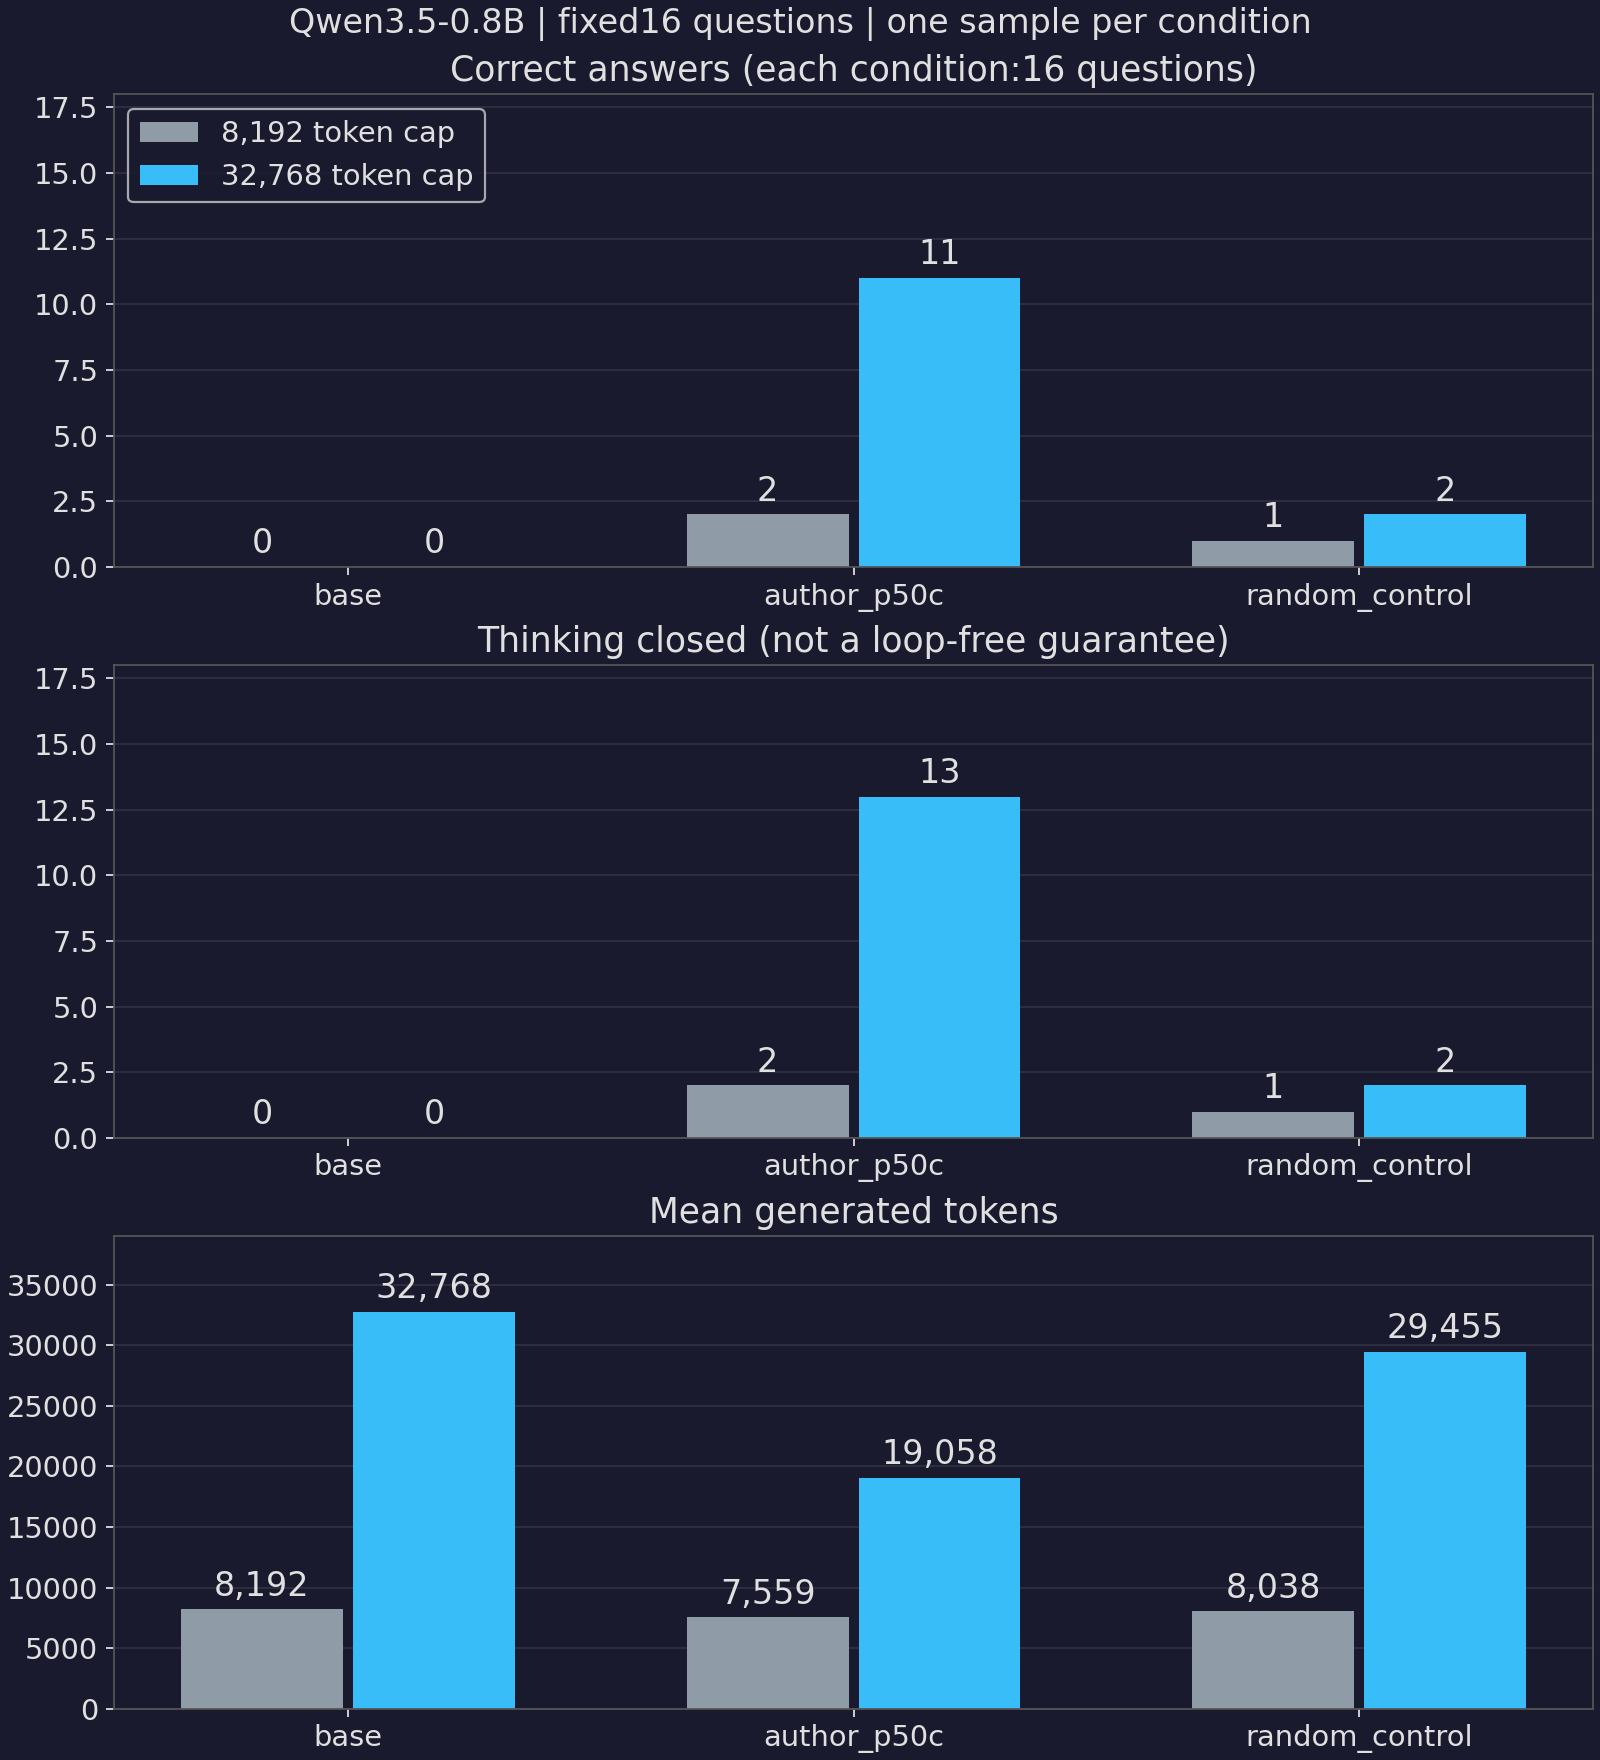

In [10]:
if not RUN_GPU:
    import gzip, urllib.request
    # Lightweight CPU dependencies only; no torch/vLLM/model loading in this path.
    for dist,version in [('math-verify','0.9.0'),('matplotlib','3.10.0')]:
        try: installed=importlib.metadata.version(dist)
        except importlib.metadata.PackageNotFoundError: installed=None
        if installed != version:
            subprocess.run([sys.executable,'-m','pip','install',f'{dist}=={version}'],check=True)
    cache=Path('replay-cache');cache.mkdir(exist_ok=True)
    local=Path('results/l4-20261104/generations.jsonl.gz')
    if local.exists(): packed=local.read_bytes()
    else:
        packed=urllib.request.urlopen('https://raw.githubusercontent.com/chengwulongxia-rgb/deep-dive-code/main/weight-space-programming-lab/results/l4-20261104/generations.jsonl.gz',timeout=30).read()
    assert sha_bytes(packed)=='ce573599fc5a686f2e6921d40c547010dee2b99d2329680b1e16754bc0aef379'
    corpus=cache/'math500-test.jsonl'
    if not corpus.exists():
        corpus.write_bytes(urllib.request.urlopen(f'https://huggingface.co/datasets/HuggingFaceH4/MATH-500/resolve/{DATA_REV}/test.jsonl',timeout=30).read())
    assert sha_bytes(corpus.read_bytes())==EXPECTED_SOURCE_SHA256
    selected=select_questions([json.loads(x) for x in corpus.read_text().splitlines() if x.strip()])
    answer_by_id={x['unique_id']:x['answer'] for x in selected}
    raw=[json.loads(x) for x in gzip.decompress(packed).decode().splitlines() if x.strip()]
    validate_complete(raw,[x['unique_id'] for x in selected])
    scored=[]
    for record in raw:
        assert record['user_prompt']==build_prompt(next(x['problem'] for x in selected if x['unique_id']==record['problem_id']))
        assert record['seed']==question_seed(record['problem_id'])
        scored.append(dict(record,**grade_boxed(record['text'],answer_by_id[record['problem_id']])))
    summary=aggregate(scored)
    assert not any(x['grade_error'] for x in scored)
    REPLAY_OUTPUT=Path('replay-output');REPLAY_OUTPUT.mkdir(exist_ok=True)
    write_json(REPLAY_OUTPUT/'summary.json',summary)
    plot_metrics(summary,REPLAY_OUTPUT/'metrics.png')
    print(json.dumps({'total':summary['total'],'groups':summary['groups']},ensure_ascii=False,indent=2))
    print('CPU replay only:96 existing outputs from80+16 across two historical GPU runs; no new inference.')
    from IPython.display import Image,display
    display(Image(filename=str(REPLAY_OUTPUT/'metrics.png')))
